## Recomendación: Contenido

- Recomendación basada en contenido con **TF-IDF**: descripciones de los procesos

- Búsqueda de vecinos **exacta vs. aproximada** (IVF y HNSW) sobre los vectores de proveedores

### Constantes

- `RANGO_MIN_DF`: documentos mínimos en que aparece un término para entrar al vocabulario

- `RANGO_DIM`: dimensiones de la LSA (SVD truncada del TF-IDF)

- `RANGO_IVF`: centroides del índice IVF (`nlist`) y centroides que se visitan por consulta (`nprobe`)

- `RANGO_HNSW`: vecinos por nodo del grafo HNSW (`M`) y amplitud de la búsqueda (`efSearch`)

- `K_RECALL` = 100: vecinos con los que se mide el recall de la búsqueda aproximada

- `RECALL_MIN` = 0.95: recall mínimo aceptado

In [1]:
RANGO_MIN_DF = [2, 5, 10, 20]
RANGO_DIM = [64, 128, 256, 512]
RANGO_IVF = {"nlist": [256, 1024], "nprobe": [1, 4, 16, 64]}
RANGO_HNSW = {"M": [16, 32], "ef": [64, 128, 256, 512]}
K_RECALL = 100
RECALL_MIN = 0.95

### Fórmulas

- **TF-IDF** del término $t$ en el proceso $j$; luego cada proceso se divide por su norma L2

$$w_{t,j} = \big(1 + \ln c_{t,j}\big)\cdot\left(\ln\frac{1+N}{1+df_t} + 1\right)$$

- $c_{t,j}$: veces que aparece $t$ en el proceso $j$

- $N$: procesos de entrenamiento

- $df_t$: procesos que contienen $t$

### Utilidades

In [2]:
NOTEBOOK = "c_contenido"
%run ../funciones.ipynb
%run funciones.ipynb

Note: you may need to restart the kernel to use updated packages.


In [3]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


In [4]:
import unicodedata, faiss
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from pyspark.ml.feature import StopWordsRemover

faiss.omp_set_num_threads(1)
sin_tilde = lambda s: unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode().lower()
STOP = sorted({sin_tilde(w) for w in StopWordsRemover.loadDefaultStopWords("spanish")})

### Carga

- `procesos`: texto de cada proceso (`descripcion` + `items_desc`)

- `hechos`: qué proveedor ganó cada proceso

- `participantes`: quién ofertó

In [5]:
cfg = leer_config()
ent, prov = pd.read_parquet(datos_dir / "entidades"), pd.read_parquet(datos_dir / "proveedores")
e_idx, p_idx = dict(zip(ent.entidad_key, ent.entidad_idx)), dict(zip(prov.proveedor_key, prov.proveedor_idx))

procs = pd.read_parquet(final_dir / "procesos", columns=["ocid", "entidad_key", "descripcion", "items_desc", "anio"])
procs["anio"] = procs.anio.astype(int)
d, it = procs.descripcion.fillna(""), procs.items_desc.fillna("")
procs["texto"] = np.where(d.str.upper().str.strip() == it.str.upper().str.strip(), d, d + " " + it)
hechos = pd.read_parquet(final_dir / "hechos", columns=["ocid", "proveedor_key", "anio"]).drop_duplicates()
hechos["anio"] = hechos.anio.astype(int)
part = pd.read_parquet(final_dir / "participantes", columns=["ocid", "proveedor_key", "anio"])
part["anio"] = part.anio.astype(int)
print(f"procesos {len(procs):,} | descripción = ítems en {(d.str.upper().str.strip() == it.str.upper().str.strip()).mean():.1%} | "
      f"stopwords {len(STOP)}")

procesos 235,954 | descripción = ítems en 42.2% | stopwords 306


---
### **1. Vocabulario `MIN_DF`**

- Documento = un proceso; entrena con los procesos de los años de entrenamiento

- `MAX_DF` = 0.5: un término en más de la mitad de los procesos no distingue rubros

In [6]:
def vectorizador(min_df):
    return TfidfVectorizer(strip_accents="unicode", lowercase=True, token_pattern=r"(?u)\b[a-z]{3,}\b", stop_words=STOP,
                           min_df=min_df, max_df=MAX_DF, sublinear_tf=True, dtype=np.float32)

txt_val = procs.loc[procs.anio.isin(PARTICIONES["val"][0]), "texto"]
vocab = []
for m in RANGO_MIN_DF:
    v = vectorizador(m).fit(txt_val)
    vocab.append({"min_df": m, "vocabulario": len(v.vocabulary_), "descartados_max_df": len(v.stop_words_)})
vocab = pd.DataFrame(vocab)
vocab

,min_df,vocabulario,descartados_max_df
0,2,25435,16520
1,5,12571,29384
2,10,7816,34139
3,20,4919,37036


- Con `MIN_DF = 2` el vocabulario es de 25k términos; erratas o códigos de un solo proceso

- **Con 5 quedan 12.6k**; con 10 y 20 se pierden términos de rubros chicos

- `MAX_DF = 0.5` descarta términos genéricos del procedimiento

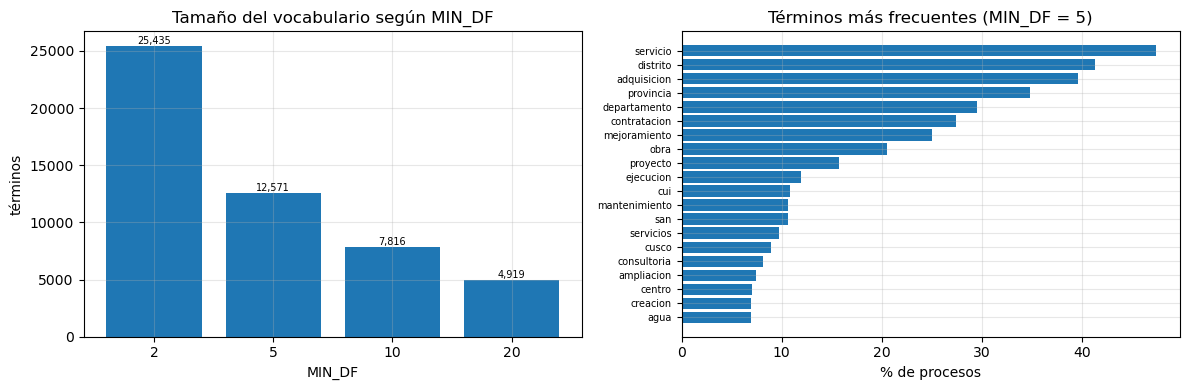

servicio        47.4
distrito        41.3
adquisicion     39.6
provincia       34.8
departamento    29.5
contratacion    27.4
mejoramiento    25.0
obra            20.5
proyecto        15.7
ejecucion       11.9
dtype: float64

In [7]:
v = vectorizador(MIN_DF)
tf_val = v.fit_transform(txt_val)
df_term = pd.Series(np.asarray((tf_val > 0).sum(0)).ravel(), index=v.get_feature_names_out())
top_terms = (100 * df_term.nlargest(20) / tf_val.shape[0]).round(1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(vocab.min_df.astype(str), vocab.vocabulario)
for j, n in enumerate(vocab.vocabulario):
    ax[0].text(j, n, f"{n:,}", ha="center", va="bottom", fontsize=7)
ax[0].set_title("Tamaño del vocabulario según MIN_DF"); ax[0].set_xlabel("MIN_DF"); ax[0].set_ylabel("términos")
ax[1].barh(top_terms.index[::-1], top_terms.values[::-1])
ax[1].set_title(f"Términos más frecuentes (MIN_DF = {MIN_DF})"); ax[1].set_xlabel("% de procesos"); ax[1].tick_params(axis="y", labelsize=7)
mostrar_fig("vocabulario")
top_terms.head(10)

---
### **2. Perfiles de entidades y proveedores**

- Cada proceso pasa por TF-IDF → **LSA** (SVD truncada) → norma L2

- **Proveedor** = promedio de los procesos que **ganó** en entrenamiento

- **Entidad** = promedio de **todos** sus procesos

- Puntaje(e, p) = coseno entre ambos perfiles

In [8]:
def perfiles(p, dim):
    anios_tr = PARTICIONES[p][0]
    pr = procs[procs.anio.isin(anios_tr)].reset_index(drop=True)
    fila = dict(zip(pr.ocid, pr.index))
    tf = vectorizador(MIN_DF).fit_transform(pr.texto)
    svd = TruncatedSVD(dim, random_state=SEED).fit(tf)
    V = normalize(svd.transform(tf)).astype(np.float32)

    def promedio(pares, col, n):
        pares = pares[pares.ocid.isin(fila)]
        A = sp.csr_matrix((np.ones(len(pares)), (pares[col].to_numpy(), pares.ocid.map(fila).to_numpy())), shape=(n, len(pr)))
        return normalize(A @ V).astype(np.float32)

    h = hechos[hechos.anio.isin(anios_tr)].assign(i=lambda x: x.proveedor_key.map(p_idx)).dropna(subset=["i"]).astype({"i": int})
    e = pr.assign(i=pr.entidad_key.map(e_idx)).dropna(subset=["i"]).astype({"i": int})
    return {"svd": svd, "V": V, "procs": pr, "fila": fila,
            "P": promedio(h, "i", cfg["n_proveedores"]), "E": promedio(e, "i", cfg["n_entidades"])}

ctx = {p: contexto(p, SENAL) for p in PARTICIONES}
perf = {p: perfiles(p, max(RANGO_DIM)) for p in PARTICIONES}
for p, f in perf.items():
    print(f"{p}: {len(f['procs']):,} procesos | proveedores con perfil {(np.abs(f['P']).sum(1) > 0).sum():,} | "
          f"entidades con perfil {(np.abs(f['E']).sum(1) > 0).sum():,}")

val: 76,390 procesos | proveedores con perfil 33,829 | entidades con perfil 2,634
test: 156,653 procesos | proveedores con perfil 61,138 | entidades con perfil 2,869


---
### **3. Dimensión de la LSA `DIM_SVD`**

- Las componentes de la SVD vienen ordenadas: un perfil de `d` dimensiones son las primeras `d` de la de 512

- Para cada `d` se compara la varianza explicada y el NDCG@10 en validación

In [9]:
def puntaje_contenido(E, P):
    return lambda idx: E[idx] @ P.T

def recortar(M, d):
    return normalize(M[:, :d]).astype(np.float32)

dims = []
c, f = ctx["val"], perf["val"]
for dm in RANGO_DIM:
    recs = top_k(puntaje_contenido(recortar(f["E"], dm), recortar(f["P"], dm)), c["entidades"], c["vistos"], c["catalogo"], k=K_EVAL)
    dims.append({"dim": dm, "varianza": round(float(f["svd"].explained_variance_ratio_[:dm].sum()), 3),
                 **evaluar(recs, c["pos"], c["catalogo"].sum())})
dims = pd.DataFrame(dims)
dims

,dim,varianza,precision@10,recall@10,ndcg@10,hit@10,cobertura
0,64,0.171,0.0190,0.0367,0.0331,0.1582,0.7161
1,128,0.247,0.0225,0.0470,0.0410,0.1839,0.7115
2,256,0.343,0.0262,0.0560,0.0472,0.2130,0.7139
3,512,0.459,0.0278,0.0607,0.0526,0.2229,0.7320


- La varianza explicada sube de 17% (64) a **46% (512)**, y el NDCG@10 de 0.033 a **0.053**

- La ganancia se reduce (0.041 → 0.047 → 0.053)

- Se fija `DIM_SVD = 512`

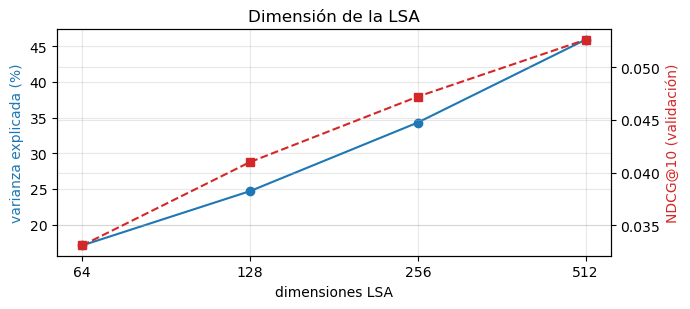

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(dims.dim, 100 * dims.varianza, "o-", color="tab:blue"); ax.set_ylabel("varianza explicada (%)", color="tab:blue")
ax.set_xscale("log", base=2); ax.set_xticks(RANGO_DIM); ax.set_xticklabels(RANGO_DIM); ax.set_xlabel("dimensiones LSA")
a2 = ax.twinx(); a2.plot(dims.dim, dims["ndcg@10"], "s--", color="tab:red"); a2.set_ylabel("NDCG@10 (validación)", color="tab:red")
ax.set_title("Dimensión de la LSA")
mostrar_fig("dimension_lsa")

In [11]:
cfg["dim_svd"] = DIM_SVD
guardar_config(cfg)
vec = {p: {"E": recortar(f["E"], DIM_SVD), "P": recortar(f["P"], DIM_SVD)} for p, f in perf.items()}

---
### **4. Búsqueda exacta vs. aproximada**

- **Prueba:** todos los proveedores que **participaron** en 2023-2024, no solo el catálogo

- Perfil = promedio de los procesos en que participó

- Consultas = perfiles de las entidades a evaluar en test

- **Exacto** (`IndexFlatIP`): compara contra todos; es la referencia del recall

- **IVF** (`IndexIVFFlat`): agrupa los vectores en `nlist` celdas (k-means) y solo revisa las `nprobe` más cercanas

- **HNSW** (`IndexHNSWFlat`): grafo navegable de `M` vecinos por nodo; `efSearch` = candidatos que mantiene al buscar

In [12]:
f = perf["test"]
pt = part[part.anio.isin(PARTICIONES["test"][0]) & part.ocid.isin(f["fila"])]
claves_amp = pd.Index(pt.proveedor_key.unique())
A = sp.csr_matrix((np.ones(len(pt)), (claves_amp.get_indexer(pt.proveedor_key), pt.ocid.map(f["fila"]).to_numpy())),
                  shape=(len(claves_amp), len(f["procs"])))
P_amp = recortar(normalize(A @ f["V"]), DIM_SVD)
Q = vec["test"]["E"][ctx["test"]["entidades"]]
print(f"base: {P_amp.shape[0]:,} proveedores × {DIM_SVD} dimensiones | consultas: {len(Q):,}")

def construir(cfg_ann, base):
    if cfg_ann["tipo"] == "exacto":
        idx = faiss.IndexFlatIP(base.shape[1])
    elif cfg_ann["tipo"] == "ivf":
        idx = faiss.IndexIVFFlat(faiss.IndexFlatIP(base.shape[1]), base.shape[1], cfg_ann["nlist"], faiss.METRIC_INNER_PRODUCT)
        idx.train(base)
    else:
        idx = faiss.IndexHNSWFlat(base.shape[1], cfg_ann["M"], faiss.METRIC_INNER_PRODUCT)
        idx.hnsw.efConstruction = 2 * cfg_ann["M"]
    idx.add(base)
    return idx

def buscar(idx, cfg_ann, Q, k):
    if cfg_ann["tipo"] == "hnsw":
        idx.hnsw.efSearch = max(cfg_ann["ef"], k)
    elif cfg_ann["tipo"] == "ivf":
        idx.nprobe = cfg_ann["nprobe"]
    return idx.search(Q, k)

t0 = time.time(); ref = construir({"tipo": "exacto"}, P_amp); t_build = time.time() - t0
t0 = time.time(); _, I_ref = buscar(ref, {"tipo": "exacto"}, Q, K_RECALL); t_q = time.time() - t0
ann = [{"tipo": "exacto", "parametros": "—", "construir_s": round(t_build, 2), "ms_consulta": round(1000 * t_q / len(Q), 3), "recall": 1.0}]
configs = ([{"tipo": "ivf", "nlist": nl, "nprobe": npr} for nl in RANGO_IVF["nlist"] for npr in RANGO_IVF["nprobe"]] +
           [{"tipo": "hnsw", "M": m, "ef": ef} for m in RANGO_HNSW["M"] for ef in RANGO_HNSW["ef"]])
cache_idx = {}
for ca in configs:
    clave = (ca["tipo"], ca.get("nlist"), ca.get("M"))
    if clave not in cache_idx:
        t0 = time.time(); cache_idx[clave] = (construir(ca, P_amp), time.time() - t0)
    idx, tb = cache_idx[clave]
    t0 = time.time(); _, I = buscar(idx, ca, Q, K_RECALL); tq = time.time() - t0
    rec = np.mean([len(set(a) & set(b)) / K_RECALL for a, b in zip(I, I_ref)])
    ann.append({"tipo": ca["tipo"], "parametros": ", ".join(f"{k}={v}" for k, v in ca.items() if k != "tipo"),
                "construir_s": round(tb, 2), "ms_consulta": round(1000 * tq / len(Q), 3), "recall": round(rec, 4)})
ann = pd.DataFrame(ann)
ann

base: 192,290 proveedores × 512 dimensiones | consultas: 2,112


,tipo,parametros,construir_s,ms_consulta,recall
0,exacto,—,0.03,2.698,1.0000
1,ivf,"nlist=256, nprobe=1",3.42,0.127,0.5805
2,ivf,"nlist=256, nprobe=4",3.42,0.441,0.8377
3,ivf,"nlist=256, nprobe=16",3.42,1.600,0.9451
4,ivf,"nlist=256, nprobe=64",3.42,5.893,0.9832
5,ivf,"nlist=1024, nprobe=1",31.85,0.079,0.4677
6,ivf,"nlist=1024, nprobe=4",31.85,0.145,0.7856
7,ivf,"nlist=1024, nprobe=16",31.85,0.445,0.9211
8,ivf,"nlist=1024, nprobe=64",31.85,1.552,0.9755
9,hnsw,"M=16, ef=64",23.68,0.184,0.8511


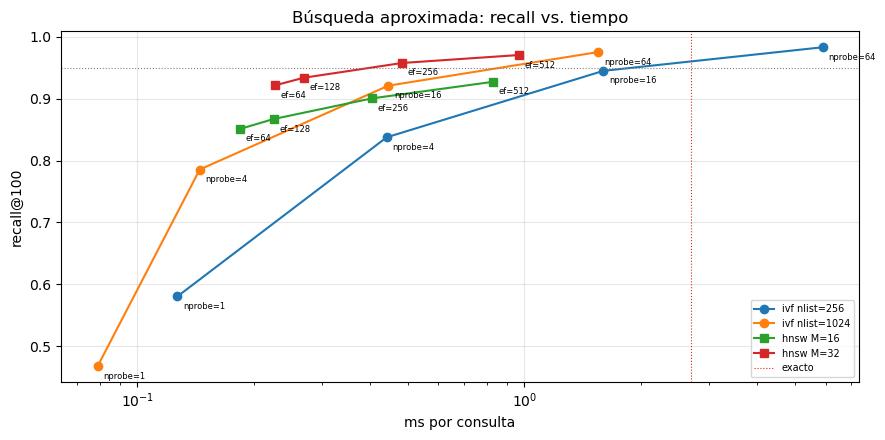

,tipo,parametros,construir_s,ms_consulta,recall
15,hnsw,"M=32, ef=256",53.22,0.483,0.9578
16,hnsw,"M=32, ef=512",53.22,0.969,0.9707
8,ivf,"nlist=1024, nprobe=64",31.85,1.552,0.9755


In [13]:
base_ann = ann[ann.tipo != "exacto"].assign(indice=lambda x: x.tipo + " " + x.parametros.str.split(", ").str[0],
                                          consulta=lambda x: x.parametros.str.split(", ").str[1])
fig, ax = plt.subplots(figsize=(9, 4.5))
for ind, d_ in base_ann.groupby("indice", sort=False):
    ax.plot(d_.ms_consulta, d_.recall, "o-" if ind.startswith("ivf") else "s-", label=ind)
    for _, r in d_.iterrows():
        ax.annotate(r.consulta, (r.ms_consulta, r.recall), textcoords="offset points", xytext=(4, -9), fontsize=6)
ax.axhline(RECALL_MIN, color="grey", ls=":", lw=.8); ax.axvline(ann.ms_consulta[0], color="tab:red", ls=":", lw=.8, label="exacto")
ax.set_xscale("log"); ax.set_xlabel("ms por consulta"); ax.set_ylabel(f"recall@{K_RECALL}")
ax.set_title("Búsqueda aproximada: recall vs. tiempo"); ax.legend(fontsize=7)
mostrar_fig("ann_recall_tiempo")
ann[(ann.tipo != "exacto") & (ann.recall >= RECALL_MIN)].nsmallest(3, "ms_consulta")

- **Exacto:** 2.70 ms por consulta sobre 192k proveedores

- **IVF** necesita `nprobe` alto para recall ≥ 0.95 (nlist=256, nprobe=64: 0.983 en 5.9 ms; con nlist=1024: 0.976 en 1.55 ms)

- **HNSW M=32, ef=256:** recall **0.958 en 0.48 ms** (5.6× más rápido que el exacto)

- Se fija HNSW (M = 32, efSearch = 256): la configuración más rápida con recall@100 ≥ 0.95

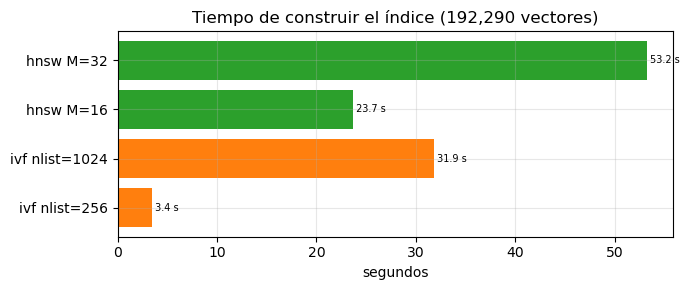

In [14]:
cons = ann[ann.tipo != "exacto"].assign(indice=lambda x: x.tipo + " " + x.parametros.str.split(",").str[0]).drop_duplicates("indice")
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(cons.indice, cons.construir_s, color=["tab:orange" if t == "ivf" else "tab:green" for t in cons.tipo])
for j, s in enumerate(cons.construir_s):
    ax.text(s, j, f" {s:.1f} s", va="center", fontsize=7)
ax.set_xlabel("segundos"); ax.set_title(f"Tiempo de construir el índice ({P_amp.shape[0]:,} vectores)")
mostrar_fig("ann_construccion")

- **IVF:** 3.4 s con 256 celdas y 32 s con 1024 (k-means más grande)

- **HNSW:** 24 s con M = 16 y 53 s con M = 32: el doble de conexiones por nodo, el doble de tiempo

In [15]:
cfg["ann"] = ANN
guardar_config(cfg)

---
### **5. Recomendación por contenido**

- Índice de faiss con los perfiles del catálogo

- Por consulta de entidad se piden `N_CAND` + vistos vecinos y se descartan los vistos

- Se compara la busqueda exacta con HNSW

In [16]:
def recs_faiss(c, E, P, cfg_ann, k=N_CAND):
    cols = np.flatnonzero(c["catalogo"])
    idx = construir(cfg_ann, P[cols])
    n_vis = int(np.asarray(c["vistos"][:, cols].sum(1)).max())
    D, I = buscar(idx, cfg_ann, E[c["entidades"]], min(k + n_vis, len(cols)))
    filas = []
    for e, dd, ii in zip(c["entidades"], D, I):
        ok = ii >= 0
        items, sc = cols[ii[ok]], dd[ok]
        nuevo = np.asarray(c["vistos"][e, items].todense()).ravel() == 0
        items, sc = items[nuevo][:k], sc[nuevo][:k]
        filas.append(pd.DataFrame({"entidad_idx": e, "rank": np.arange(len(items)) + 1, "proveedor_idx": items, "score": sc}))
    return pd.concat(filas, ignore_index=True)

evaluacion = []
for p in PARTICIONES:
    c, v = ctx[p], vec[p]
    for nombre, ca in {"contenido_exacto": {"tipo": "exacto"}, "contenido": ANN}.items():
        t0 = time.time(); recs = recs_faiss(c, v["E"], v["P"], ca)
        guardar_recs(recs, f"{nombre}_{p}")
        evaluacion.append({"particion": p, "modelo": nombre, **evaluar(recs, c["pos"], c["catalogo"].sum()), "seg": round(time.time() - t0, 1)})
evaluacion = pd.DataFrame(evaluacion)
evaluacion

,particion,modelo,precision@10,recall@10,ndcg@10,hit@10,cobertura,seg
0,val,contenido_exacto,0.0278,0.0607,0.0526,0.2229,0.7320,1.2
1,val,contenido,0.0278,0.0607,0.0526,0.2224,0.7318,2.8
2,test,contenido_exacto,0.0204,0.0465,0.0364,0.1728,0.5395,1.3
3,test,contenido,0.0203,0.0464,0.0363,0.1723,0.5391,5.1


- **Contenido: NDCG@10 = 0.036 en test** (0.053 en validación)

- HNSW da el **mismo NDCG que el exacto** (diferencias < 0.001)

- Mayor cobertura (54% del catálogo): recomienda proveedores poco populares del mismo rubro

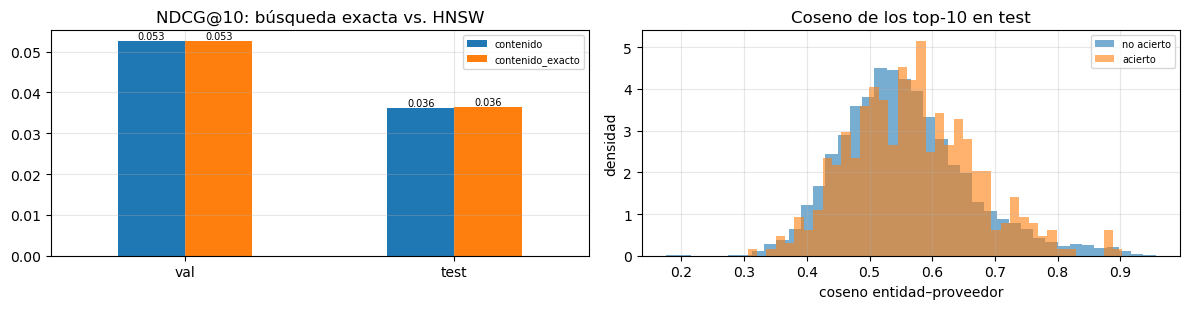

,count,25%,50%,75%
acierto,,,,
False,20691.0,0.486,0.545,0.611
True,429.0,0.498,0.563,0.635


In [17]:
c = ctx["test"]
r = leer_recs("contenido_test")
r = r[r["rank"] <= K_EVAL].copy()
r["acierto"] = [x in c["pos"].get(e, set()) for e, x in zip(r.entidad_idx, r.proveedor_idx)]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
t = evaluacion.pivot(index="particion", columns="modelo", values="ndcg@10").loc[list(PARTICIONES)]
t.plot.bar(ax=ax[0], rot=0)
for cont in ax[0].containers:
    ax[0].bar_label(cont, fmt="%.3f", fontsize=7)
ax[0].set_title("NDCG@10: búsqueda exacta vs. HNSW"); ax[0].set_xlabel(""); ax[0].legend(fontsize=7)
ax[1].hist(r.score[~r.acierto], bins=40, alpha=.6, density=True, label="no acierto")
ax[1].hist(r.score[r.acierto], bins=40, alpha=.6, density=True, label="acierto")
ax[1].set_title("Coseno de los top-10 en test"); ax[1].set_xlabel("coseno entidad–proveedor"); ax[1].set_ylabel("densidad"); ax[1].legend(fontsize=7)
mostrar_fig("contenido_evaluacion")
separacion = r.groupby("acierto").score.describe()[["count", "25%", "50%", "75%"]].round(3)
separacion

- Exacto y HNSW dan el **mismo NDCG** en validación (0.053) y en test (0.036)

- En test, 429 de los 21,120 recomendados en el top-10 son aciertos (2%)

- Coseno mediano: **0.563 en los aciertos vs. 0.545 en los no aciertos**

- El coseno encuentra el rubro, pero no distingue quién gana dentro de él

---
### **6. Catálogo ampliado: proveedores que solo ofertaron**

- El filtrado colaborativo no puede proponer a un proveedor que nunca ganó (`frio_proveedor`)

- Por contenido sí, si **ofertó** antes: su perfil sale de los procesos en que participó

- Se evalúa sobre los pares fríos de 2025 cuyo proveedor tiene perfil

In [18]:
c = ctx["test"]
frios = c["ev"][c["ev"].tipo == "frio_proveedor"].merge(prov[["proveedor_idx", "proveedor_key"]], on="proveedor_idx")
frios = frios[frios.proveedor_key.isin(claves_amp) & frios.entidad_idx.isin(np.flatnonzero(np.abs(vec["test"]["E"]).sum(1) > 0))]
pos_frio = frios.groupby("entidad_idx").proveedor_key.apply(set).to_dict()

ganadores = set(prov.proveedor_key[c["vistos"].sum(0).A1 > 0])
solo_ofertan = np.array([k not in ganadores for k in claves_amp])
base_frio = P_amp[solo_ofertan]
claves_frio = claves_amp[solo_ofertan]
idx_frio = construir(ANN, base_frio)
ents = np.array(sorted(pos_frio))
_, I = buscar(idx_frio, ANN, vec["test"]["E"][ents], K_EVAL)
aciertos = [len(set(claves_frio[i]) & pos_frio[e]) for e, i in zip(ents, I)]
amp = pd.DataFrame([{
    "pares_frio_proveedor": int((c["ev"].tipo == "frio_proveedor").sum()), "con_perfil_de_oferta": len(frios),
    "pct_con_perfil": round(100 * len(frios) / (c["ev"].tipo == "frio_proveedor").sum(), 1),
    "base_solo_ofertan": int(solo_ofertan.sum()), "entidades": len(ents),
    "hit@10": round(np.mean([a > 0 for a in aciertos]), 4),
    "recall@10": round(np.mean([a / len(pos_frio[e]) for a, e in zip(aciertos, ents)]), 4),
    "hit@10_azar": round(1 - np.mean([np.prod([1 - K_EVAL / (len(claves_frio) - j) for j in range(len(pos_frio[e]))]) for e in ents]), 4)}])
amp

,pares_frio_proveedor,con_perfil_de_oferta,pct_con_perfil,base_solo_ofertan,entidades,hit@10,recall@10,hit@10_azar
0,26054,4652,17.9,131149,1498,0.1142,0.0488,0.0002


- De 26,054 pares fríos de 2025, **4,652 (17.9%) tienen un proveedor que había ofertado**

- Sobre 131k proveedores que solo ofertaron, el contenido acierta al menos uno en el **11.4% de las entidades**

- El contenido ve **mercado potencial** invisible para el colaborativo

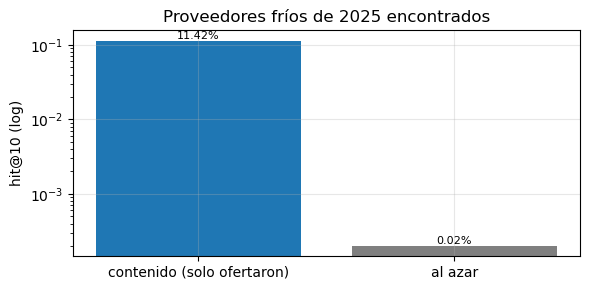

In [19]:
fig, ax = plt.subplots(figsize=(6, 3))
vals = {"contenido (solo ofertaron)": amp["hit@10"][0], "al azar": amp["hit@10_azar"][0]}
ax.bar(vals.keys(), vals.values(), color=["tab:blue", "tab:gray"]); ax.set_yscale("log")
for j, v in enumerate(vals.values()):
    ax.text(j, v, f"{100 * v:.2f}%", ha="center", va="bottom", fontsize=8)
ax.set_ylabel("hit@10 (log)"); ax.set_title("Proveedores fríos de 2025 encontrados")
mostrar_fig("catalogo_ampliado")

---
### **7. Ejemplo: proveedores parecidos por contenido**

Vecinos de un proveedor grande en el espacio de texto

In [20]:
P = vec["test"]["P"]
p0 = int(prov.index[prov.proveedor_key == "RUC:20501887286"][0]) if (prov.proveedor_key == "RUC:20501887286").any() else int(c["vistos"].sum(0).A1.argmax())
cols = np.flatnonzero(c["catalogo"])
sim = P[cols] @ P[p0]
top = cols[np.argsort(-sim)[1:9]]
parecidos = prov.loc[top, ["proveedor_key", "nombre"]].assign(similitud=(P[top] @ P[p0]).round(3))
print("proveedor:", prov.nombre[p0])
parecidos

proveedor: DIAGNOSTICA PERUANA S.A.C.


,proveedor_key,nombre,similitud
20,RUC:20553853355,SIMED PERU S.A.C.,0.927
71,RUC:20468787360,ROCHEM BIOCARE DEL PERU S.A.C,0.860
30,RUC:20155695901,SISTEMAS ANALITICOS SRL,0.856
117,RUC:20100177341,PRODUCTOS ROCHE Q F S A,0.847
44,RUC:20505110651,W.P. BIOMED SOCIEDAD ANONIMA,0.833
383,RUC:20524800510,LAB & HEALTH SUPPLY S.A.C.,0.826
1287,RUC:20607850209,GALENICA PERU S.A.C.,0.825
156,RUC:20537139120,DELTALAB PERU S.A.C.,0.817


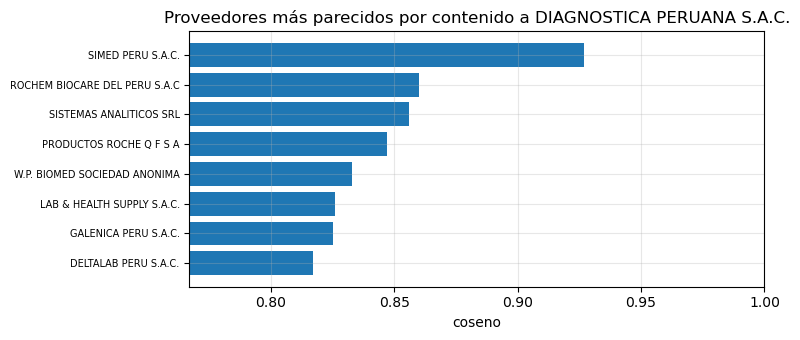

In [21]:
fig, ax = plt.subplots(figsize=(8, 3.5))
v = parecidos.iloc[::-1]
ax.barh(v.nombre.str[:45], v.similitud); ax.set_xlim(v.similitud.min() - .05, 1)
ax.set_xlabel("coseno"); ax.set_title(f"Proveedores más parecidos por contenido a {prov.nombre[p0]}"); ax.tick_params(axis="y", labelsize=7)
mostrar_fig("parecidos_ejemplo")

- Los vecinos de Diagnóstica Peruana son proveedores de **diagnóstico y laboratorio clínico** (Simed, Rochem Biocare, Roche)

- El texto agrupa por **qué se vende**, no por a quién

---
### **8. Escritura de datos**

- `temp/datos/vec_proveedor_<particion>` y `vec_entidad_<particion>`: perfiles LSA de `DIM_SVD` dimensiones

- `temp/datos/recs_contenido[_exacto]_<particion>`: top-`N_CAND` por entidad

In [22]:
for p, v in vec.items():
    np.save(datos_dir / f"vec_proveedor_{p}.npy", v["P"])
    np.save(datos_dir / f"vec_entidad_{p}.npy", v["E"])

#### a. Verificación

In [23]:
for p in PARTICIONES:
    c = ctx[p]
    for m in ["contenido", "contenido_exacto"]:
        r = leer_recs(f"{m}_{p}")
        assert set(r.entidad_idx) <= set(c["pos"]) and c["catalogo"][r.proveedor_idx].all(), (m, p)
        assert c["vistos"][r.entidad_idx.to_numpy(), r.proveedor_idx.to_numpy()].sum() == 0, (m, p)
    assert np.load(datos_dir / f"vec_proveedor_{p}.npy").shape == (cfg["n_proveedores"], DIM_SVD)
    print(f"{p}: recomendaciones dentro del catálogo y sin pares vistos | perfiles {DIM_SVD}-d | OK")

val: recomendaciones dentro del catálogo y sin pares vistos | perfiles 512-d | OK


test: recomendaciones dentro del catálogo y sin pares vistos | perfiles 512-d | OK


---
### **9. Escritura de resultados**

In [24]:
escritos = guardar_tablas({"vocabulario": vocab, "terminos_frecuentes": top_terms.rename("pct_procesos").reset_index().rename(columns={"index": "termino"}),
                           "dimension_lsa": dims, "ann_benchmark": ann, "evaluacion_contenido": evaluacion,
                           "separacion_puntaje": separacion.reset_index(), "catalogo_ampliado": amp, "parecidos_ejemplo": parecidos})

Escrito en 03_Recomend/temp/c_contenido/: vocabulario, terminos_frecuentes, dimension_lsa, ann_benchmark, evaluacion_contenido, separacion_puntaje, catalogo_ampliado, parecidos_ejemplo


#### a. Verificación

In [25]:
verificar_salidas(escritos)

OK: 8 tablas (parquet + json) | 7 figuras: ann_construccion, ann_recall_tiempo, catalogo_ampliado, contenido_evaluacion, dimension_lsa, parecidos_ejemplo, vocabulario


---
### **10. Cerrar sesión**

In [26]:
spark.stop()